<a href="https://colab.research.google.com/github/mabdullahecon/instrumental-variables-2sls-automobiles/blob/main/notebooks/IVnotebook1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# When the Instruments Fail: Testing Price Endogeneity and Logit IV in the U.S. Auto Market

## OLS, 2SLS, and LIML estimates of automobile demand using the BLP data, 1971–1990

### What this project is about

The U.S. automobile industry is a differentiated product market where manufacturers compete through vehicles with varying prices and characteristics, including fuel efficiency, horsepower, and size. Consumers choose between these vehicles based on their preferences, budgets, and the features they value.

Understanding how consumers respond to automobile prices is important for studying competition. However, prices also reflect factors such as brand reputation, perceived quality, and other difficult-to-observe product characteristics. Since these factors can influence both prices and demand, they create an endogeneity problem when estimating the relationship between the two.

This project asks three questions about the U.S. automobile market from 1971 to 1990: (1) How much does correcting for price endogeneity change the estimated price sensitivity? (2) Are the standard BLP instruments valid and strong? (3) Are the resulting logit demand estimates economically plausible?

Using the BLP dataset (2,217 vehicle-year observations), the analysis compares OLS, 2SLS, and LIML estimates, tests instrument strength and validity, varies the instrument sets and fixed effects, and checks the implied elasticities and marginal costs. The main finding is that the simple logit IV estimates are not credible: the instruments either fail the overidentification test or, when fixed effects remove that failure, become too weak to rely on.

### The Data

In [35]:
!pip install -q "requests==2.32.4" pyblp mermaid-py linearmodels

import pandas as pd
import numpy as np
import pyblp
import matplotlib.pyplot as plt
from IPython.display import Image, display
from mermaid import Mermaid
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS, IVLIML

In [2]:
import os, matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
_count, _show = [0], plt.show

def _save_and_show(*args, **kwargs):
    _count[0] += 1
    plt.savefig(f"figures/fig{_count[0]:02d}.png", dpi=150, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show

In [3]:
df = pd.read_csv(pyblp.data.BLP_PRODUCTS_LOCATION)

This project uses the Berry, Levinsohn, and Pakes (BLP) automobile dataset, covering the U.S. market from 1971 to 1990. It contains 2,217 observations. Each year is a market (20 markets), and each observation is a vehicle in that market.

The dataset includes vehicle prices, market shares, product characteristics such as horsepower-to-weight ratio, fuel efficiency, and space, as well as vehicle, manufacturer, and market identifiers. It also provides demand-side and supply-side instrumental variables to address price endogeneity.


In [4]:
print(df.shape)
print(df.columns.tolist())
df.head()

(2217, 33)
['market_ids', 'clustering_ids', 'car_ids', 'firm_ids', 'region', 'shares', 'prices', 'hpwt', 'air', 'mpd', 'mpg', 'space', 'trend', 'demand_instruments0', 'demand_instruments1', 'demand_instruments2', 'demand_instruments3', 'demand_instruments4', 'demand_instruments5', 'demand_instruments6', 'demand_instruments7', 'supply_instruments0', 'supply_instruments1', 'supply_instruments2', 'supply_instruments3', 'supply_instruments4', 'supply_instruments5', 'supply_instruments6', 'supply_instruments7', 'supply_instruments8', 'supply_instruments9', 'supply_instruments10', 'supply_instruments11']


,market_ids,clustering_ids,car_ids,firm_ids,region,shares,prices,hpwt,air,mpd,...,supply_instruments2,supply_instruments3,supply_instruments4,supply_instruments5,supply_instruments6,supply_instruments7,supply_instruments8,supply_instruments9,supply_instruments10,supply_instruments11
0,1971,AMGREM71,129,15,US,0.001051,4.935802,0.528997,0,1.888146,...,0.0,1.705933,1.595656,87.0,-61.959985,0.0,46.060389,29.786989,0.0,1.888146
1,1971,AMHORN71,130,15,US,0.000670,5.516049,0.494324,0,1.935989,...,0.0,1.680910,1.490295,87.0,-61.959985,0.0,46.060389,29.786989,0.0,1.935989
2,1971,AMJAVL71,132,15,US,0.000341,7.108642,0.467613,0,1.716799,...,0.0,1.801067,1.357703,87.0,-61.959985,0.0,46.060389,29.786989,0.0,1.716799
3,1971,AMMATA71,134,15,US,0.000522,6.839506,0.426540,0,1.687871,...,0.0,1.818061,1.261347,87.0,-61.959985,0.0,46.060389,29.786989,0.0,1.687871
4,1971,AMAMBS71,136,15,US,0.000442,8.928395,0.452489,0,1.504286,...,0.0,1.933210,1.237365,87.0,-61.959985,0.0,46.060389,29.786989,0.0,1.504286


In [5]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2217 entries, 0 to 2216
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   market_ids            2217 non-null   int64  
 1   clustering_ids        2217 non-null   object 
 2   car_ids               2217 non-null   int64  
 3   firm_ids              2217 non-null   int64  
 4   region                2217 non-null   object 
 5   shares                2217 non-null   float64
 6   prices                2217 non-null   float64
 7   hpwt                  2217 non-null   float64
 8   air                   2217 non-null   int64  
 9   mpd                   2217 non-null   float64
 10  mpg                   2217 non-null   float64
 11  space                 2217 non-null   float64
 12  trend                 2217 non-null   int64  
 13  demand_instruments0   2217 non-null   float64
 14  demand_instruments1   2217 non-null   float64
 15  demand_instruments2  

,0
market_ids,0
clustering_ids,0
car_ids,0
firm_ids,0
region,0
shares,0
prices,0
hpwt,0
air,0
mpd,0


Calculate total vehicle market shares by year and derive the implied outside-good share, representing consumers who do not purchase any of the included vehicles.

Construct the log market-share ratio, which measures each vehicle's market share relative to the outside good and serves as the dependent variable in the demand estimation.

In [6]:
# Calculate total observed vehicle market share in each year.
share_summary = df.groupby('market_ids')['shares'].agg(
    ['sum', 'min', 'max']
)

# Calculate the implied outside-good share.
share_summary['outside_share'] = 1 - share_summary['sum']

display(share_summary)

,sum,min,max,outside_share
market_ids,,,,
1971,0.119894,3.298038e-05,0.008658,0.880106
1972,0.128605,1.292289e-05,0.009473,0.871395
1973,0.114224,7.014130e-07,0.006878,0.885776
1974,0.105466,2.768836e-05,0.007878,0.894534
1975,0.108198,2.824324e-05,0.005491,0.891802
1976,0.124690,1.683256e-05,0.006941,0.875310
1977,0.122111,2.038669e-05,0.006944,0.877889
1978,0.122168,7.668434e-06,0.006728,0.877832
1979,0.104483,1.925077e-05,0.004651,0.895517


In [7]:
df['outside_share'] = (
    1 - df.groupby('market_ids')['shares'].transform('sum')
)

df['log_share_ratio'] = (
    np.log(df['shares']) - np.log(df['outside_share'])
)

In [8]:
print("All outside shares positive:",
      (df['outside_share'] > 0).all())

print("One outside share per market:",
      df.groupby('market_ids')['outside_share'].nunique().max() == 1)

All outside shares positive: True
One outside share per market: True


### Exploring the Data

#### Descriptive Statistics

In [9]:
variables = [
    'prices', 'shares', 'hpwt',
    'air', 'mpd', 'mpg', 'space']

display(df[variables].describe().T)

,count,mean,std,min,25%,50%,75%,max
prices,2217.0,11.761420,8.643777,3.393267e+00,6.713755,8.728650,13.074074,68.596774
shares,2217.0,0.000973,0.001145,7.014130e-07,0.000186,0.000570,0.001286,0.009473
hpwt,2217.0,0.394375,0.096643,1.704545e-01,0.336585,0.375049,0.427509,0.947581
air,2217.0,0.241768,0.428251,0.000000e+00,0.000000,0.000000,0.000000,1.000000
mpd,2217.0,2.084870,0.698056,8.460695e-01,1.557015,2.010417,2.482848,6.436827
mpg,2217.0,2.099643,0.581070,9.130000e-01,1.700000,2.000000,2.500000,5.300000
space,2217.0,1.310159,0.237637,7.560000e-01,1.131279,1.269827,1.452700,1.888000


The dataset contains 2,217 observations across all variables, with no missing values. Automobile prices have a mean of 11.76 and a median of 8.73, indicating some variation across vehicle models. Market shares are relatively small, with a mean of 0.00097, reflecting the large number of competing products. Product characteristics also vary considerably, particularly horsepower-to-weight ratio and fuel efficiency, while air conditioning is present in approximately 24.2% of observations.

#### Distribution of Automobile Prices

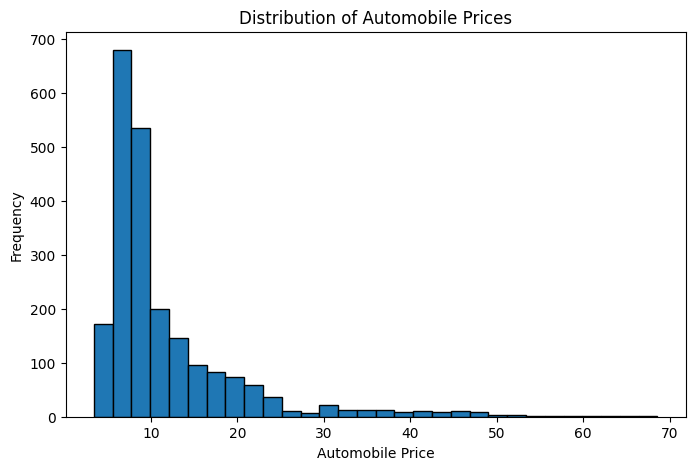

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df['prices'], bins=30, edgecolor='black')

plt.xlabel('Automobile Price')
plt.ylabel('Frequency')
plt.title('Distribution of Automobile Prices')

plt.show()

#### Distribution of Market Shares

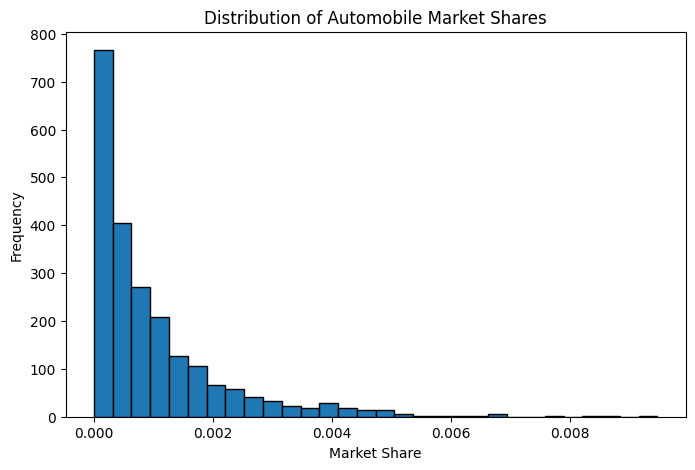

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df['shares'], bins=30, edgecolor='black')

plt.xlabel('Market Share')
plt.ylabel('Frequency')
plt.title('Distribution of Automobile Market Shares')

plt.show()

Automobile prices are strongly right-skewed, with most vehicles concentrated in the lower price range and relatively few high-priced models. Market shares are also right-skewed, indicating that most individual vehicle models account for a small proportion of total market demand, while a smaller number capture larger shares. Both distributions highlight substantial variation across automobile models.

#### Manufacturer Concentration over Time

Calculate each manufacturer's total market share within each year, then calculate the Herfindahl-Hirschman Index (HHI) as the sum of squared manufacturer market shares.


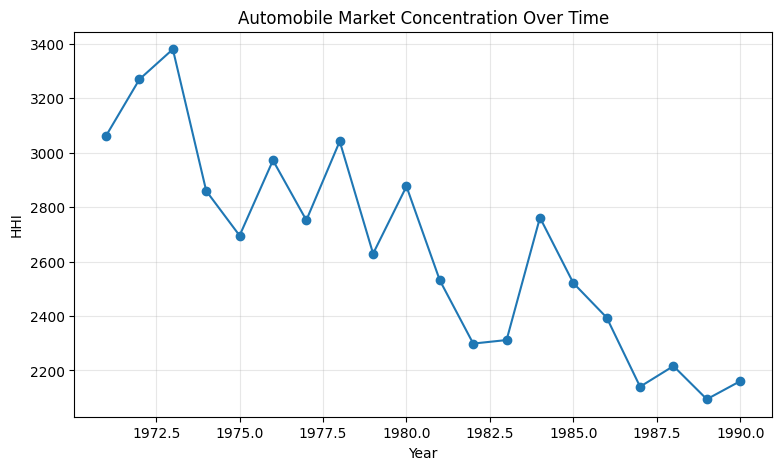

In [12]:
# Aggregate vehicle shares at the manufacturer-year level.
firm_shares = df.groupby(['market_ids', 'firm_ids'])['shares'].sum().reset_index()

# Calculate the HHI for each year.
df['inside_share'] = df['shares'] / df.groupby('market_ids')['shares'].transform('sum')
firm_shares = df.groupby(['market_ids','firm_ids'])['inside_share'].sum().reset_index()
hhi = (firm_shares.groupby('market_ids')['inside_share']
         .apply(lambda s: (s**2).sum()*10000).reset_index(name='HHI'))
# Plot market concentration over time.
plt.figure(figsize=(9, 5))
plt.plot(hhi['market_ids'], hhi['HHI'], marker='o')

plt.xlabel('Year')
plt.ylabel('HHI')
plt.title('Automobile Market Concentration Over Time')
plt.grid(alpha=0.3)
plt.show()

#### Automobile prices versus market share

This scatter plot examines the relationship between vehicle prices and market shares across all observations. Since market shares are highly skewed, we use a logarithmic scale on the y-axis to make differences easier to see.

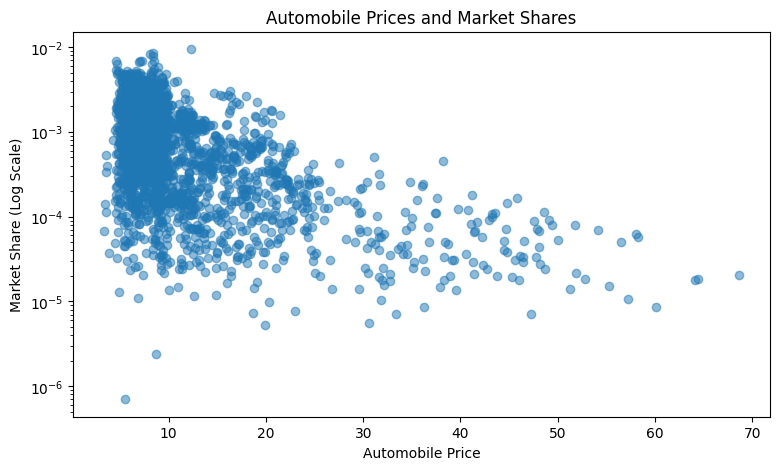

In [13]:
plt.figure(figsize=(9, 5))

plt.scatter(df['prices'], df['shares'], alpha=0.5)

plt.yscale('log')
plt.xlabel('Automobile Price')
plt.ylabel('Market Share (Log Scale)')
plt.title('Automobile Prices and Market Shares')

plt.show()


The scatter plot shows a general inverse relationship between automobile price ($p$) and market share ($s$), where higher-priced vehicles tend to capture significantly smaller market shares. Most vehicles are concentrated in the lower price range ($p < 20$) with market shares primarily clustered between $10^{-4}$ and $10^{-2}$ on the logarithmic scale. As vehicle price increases toward $70$, market shares taper off systematically down toward $10^{-5}$ and below, reflecting lower consumer demand for premium-priced cars.




### The Identification Problem

#### Why are automobile prices endogenous?

Automobile prices may be endogenous because manufacturers consider both observable and unobservable product characteristics when setting prices. Observable characteristics include horsepower, fuel efficiency, and vehicle space, while unobservable characteristics include brand appeal, reliability, and perceived quality.

These unobservable characteristics can influence both the price of a vehicle and its demand. For example, a vehicle with a strong brand reputation may command a higher price while also attracting more consumers. This creates a correlation between price and the unobserved demand component, violating a key OLS assumption and potentially biasing the estimated price coefficient.

#### The Demand Equation

We use the following logit demand equation to estimate how automobile prices and product characteristics affect consumer demand:

$$
\log(s_{jt})-\log(s_{0t}) = \alpha p_{jt}+X_{jt}'\beta+\xi_{jt}
$$

The dependent variable is the logarithm of the ratio between a vehicle's market share and the outside-good share. This specification comes from the logit model of consumer choice, where consumers choose between available vehicle models and an outside option, such as not purchasing any of the vehicles in the dataset.

The equation relates this market-share ratio to vehicle prices and observed product characteristics. The unobserved component, $\xi_{jt}$, captures product characteristics that affect demand but are not included in the dataset. Our main interest is $\alpha$, which measures how demand responds to changes in automobile prices.

#### Instrumental Variables

To address price endogeneity, we use instrumental variables (IV), which allow us to isolate variation in automobile prices that is unrelated to unobserved demand characteristics. A valid instrument must satisfy two principles:

1. **Relevance:** The instrument must be correlated with automobile prices. This ensures that it provides useful information for explaining price variation.

2. **Exogeneity (exclusion restriction):** The instrument must not be correlated with unobserved factors affecting demand and must influence consumer demand only through its effect on price.



### Instrument Construction

To address price endogeneity, this analysis uses the demand-side instrumental variables provided in the BLP dataset. We will discuss the instruments later.

We begin by examining the descriptive statistics of the eight demand-side instruments to understand their distributions, variation, and ranges across the 2,217 observations.

In [15]:
demand_instruments = [f'demand_instruments{i}' for i in range(8)]

display(df[demand_instruments].describe().T)

,count,mean,std,min,25%,50%,75%,max
demand_instruments0,2217.0,14.330176,11.920962,0.000000,4.000000,13.000000,27.000000,39.000000
demand_instruments1,2217.0,5.582260,4.754802,0.000000,1.435634,4.586556,9.585661,17.030041
demand_instruments2,2217.0,3.332882,4.470841,0.000000,0.000000,2.000000,4.000000,19.000000
demand_instruments3,2217.0,29.192992,27.019724,0.000000,7.458168,21.144850,43.518393,106.169873
demand_instruments4,2217.0,99.754623,23.587005,51.000000,81.000000,98.000000,115.000000,149.000000
demand_instruments5,2217.0,39.799326,11.720506,18.280749,31.076570,38.011288,49.327463,66.347031
demand_instruments6,2217.0,27.355435,21.357980,0.000000,8.000000,23.000000,42.000000,74.000000
demand_instruments7,2217.0,216.794185,90.831823,82.390308,142.441744,175.297045,302.252748,408.047463


All eight instruments contain 2,217 observations, with no missing values. Their values vary considerably, reflecting differences in the characteristics and number of other vehicles offered by manufacturers and their competitors.

The following scatterplots examine the relationship between each demand-side instrument and automobile prices. They provide an initial visual assessment of instrument relevance by showing whether changes in instrument values are associated with differences in prices.

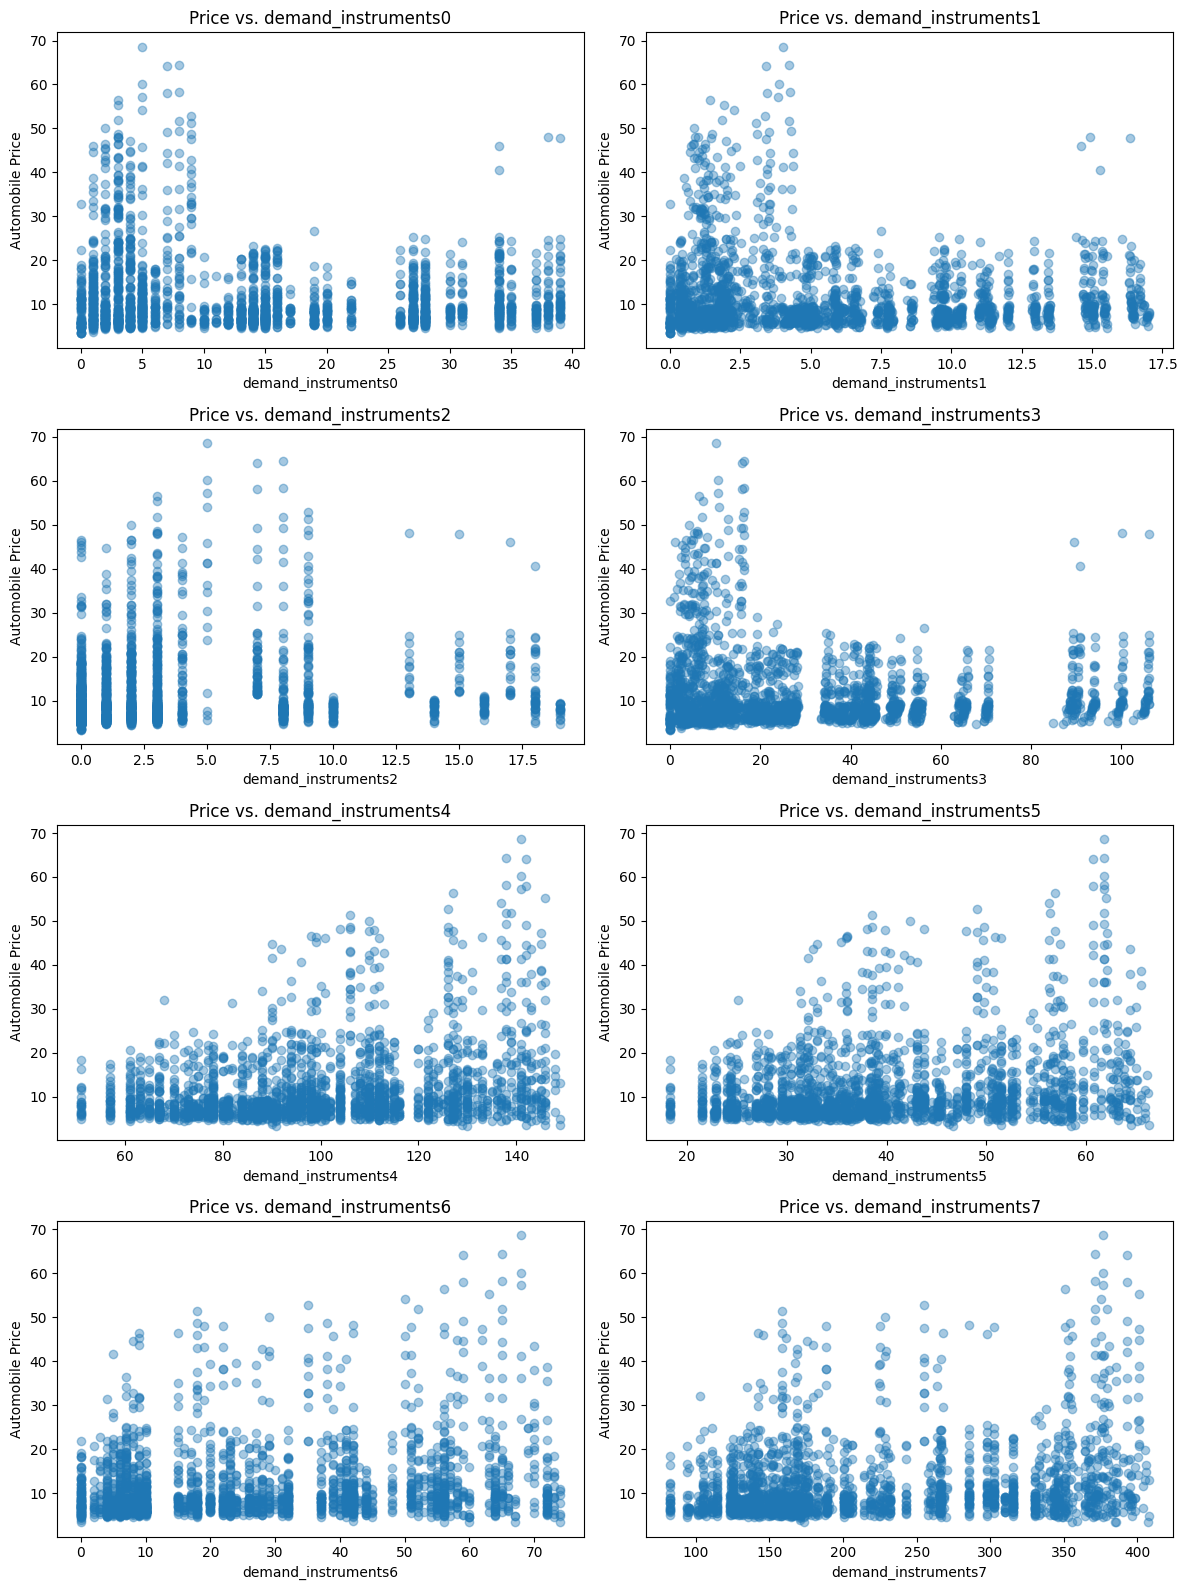

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, ax in enumerate(axes.flatten()):
    instrument = f'demand_instruments{i}'
    ax.scatter(df[instrument], df['prices'], alpha=0.4)
    ax.set_xlabel(instrument)
    ax.set_ylabel('Automobile Price')
    ax.set_title(f'Price vs. {instrument}')

plt.tight_layout()
plt.show()

In [17]:
variables = (
    ['prices'] +
    demand_instruments +
    ['hpwt', 'air', 'mpd', 'mpg', 'space']
)

correlation_matrix = df[variables].corr()

display(correlation_matrix.round(2))

,prices,demand_instruments0,demand_instruments1,demand_instruments2,demand_instruments3,demand_instruments4,demand_instruments5,demand_instruments6,demand_instruments7,hpwt,air,mpd,mpg,space
prices,1.00,-0.14,-0.11,0.13,-0.10,0.29,0.27,0.22,0.26,0.51,0.67,-0.24,-0.35,0.18
demand_instruments0,-0.14,1.00,0.98,0.69,0.93,-0.39,-0.27,-0.02,-0.14,-0.06,-0.03,-0.08,-0.17,0.37
demand_instruments1,-0.11,0.98,1.00,0.70,0.93,-0.36,-0.22,0.01,-0.09,0.03,-0.01,-0.04,-0.18,0.37
demand_instruments2,0.13,0.69,0.70,1.00,0.79,0.08,0.17,0.33,0.25,0.04,0.24,0.17,0.02,0.07
demand_instruments3,-0.10,0.93,0.93,0.79,1.00,-0.15,-0.03,0.20,0.11,-0.00,0.04,0.13,-0.06,0.23
demand_instruments4,0.29,-0.39,-0.36,0.08,-0.15,1.00,0.95,0.88,0.91,0.20,0.32,0.54,0.37,-0.45
demand_instruments5,0.27,-0.27,-0.22,0.17,-0.03,0.95,1.00,0.92,0.95,0.28,0.32,0.59,0.30,-0.38
demand_instruments6,0.22,-0.02,0.01,0.33,0.20,0.88,0.92,1.00,0.93,0.21,0.32,0.57,0.29,-0.30
demand_instruments7,0.26,-0.14,-0.09,0.25,0.11,0.91,0.95,0.93,1.00,0.26,0.34,0.65,0.27,-0.32
hpwt,0.51,-0.06,0.03,0.04,-0.00,0.20,0.28,0.21,0.26,1.00,0.33,-0.07,-0.29,0.05


The correlations with prices vary across the instruments. The strongest positive correlations are observed for `demand_instruments4` (0.29), `demand_instruments5` (0.27), `demand_instruments6` (0.22), and `demand_instruments7` (0.26), while instruments 0–3 have relatively weak correlations with prices. The instruments are also highly correlated with one another, particularly within groups 0–3 and 4–7, suggesting potential multicollinearity if several are included together. These correlations provide an initial indication of relevance but do not establish whether the instruments are valid.

### Model 1: Baseline OLS Demand Estimation

The first model estimates a differentiated-product logit demand equation using ordinary least squares (OLS). The log of each vehicle's market share relative to the outside good is regressed on its price and observed product characteristics, including horsepower-to-weight ratio, air conditioning, fuel efficiency, and vehicle space.

$$
\log(s_{jt})-\log(s_{0t}) = \alpha p_{jt}+\beta_1 hpwt_{jt}+\beta_2 air_{jt} +\beta_3 mpd_{jt}+\beta_4 mpg_{jt}+\beta_5 space_{jt}+\xi_{jt}
$$

This provides a baseline estimate of the relationship between price and demand before accounting for price endogeneity through instrumental variables. Heteroskedasticity-robust standard errors are used for statistical inference.

In [18]:
ols_model = smf.ols(
    'log_share_ratio ~ prices + hpwt + air + mpd + mpg + space',
    data=df
).fit(cov_type='HC1')

# Display the OLS regression results.
ols_table = pd.DataFrame({
    'Coefficient': ols_model.params,
    'Robust SE': ols_model.bse,
    'p-value': ols_model.pvalues,
    'CI Lower': ols_model.conf_int()[0],
    'CI Upper': ols_model.conf_int()[1]
})

display(ols_table.round(4))
print(f'Observations: {int(ols_model.nobs)}')
print(f'R-squared: {ols_model.rsquared:.4f}')

,Coefficient,Robust SE,p-value,CI Lower,CI Upper
Intercept,-11.3535,0.3778,0.0000,-12.0939,-10.6131
prices,-0.0884,0.0044,0.0000,-0.0970,-0.0799
hpwt,0.3980,0.3026,0.1885,-0.1951,0.9912
air,-0.0015,0.0709,0.9832,-0.1405,0.1375
mpd,0.0987,0.0541,0.0681,-0.0073,0.2047
mpg,0.4116,0.0830,0.0000,0.2489,0.5742
space,2.7605,0.1558,0.0000,2.4550,3.0659


Observations: 2217
R-squared: 0.3942


The OLS results show a negative and statistically significant price coefficient of -0.0884, indicating that a one-unit increase in automobile price is associated with an approximately 0.0884 decrease in the log market-share ratio, holding observed characteristics constant. Its 95% confidence interval ranges from -0.0970 to -0.0799, excluding zero. Among the observed characteristics, fuel efficiency (mpg) and vehicle space have positive, statistically significant coefficients, while horsepower-to-weight ratio, air conditioning, and miles per dollar are not statistically significant at the 5% level. The model has an R-squared of 0.3942, meaning that the explanatory variables account for approximately 39.4% of the variation in the log market-share ratio across 2,217 observations.

However, the negative price coefficient should not yet be interpreted as a causal estimate. Unobserved characteristics such as brand reputation and perceived quality may influence both prices and consumer demand, creating a correlation between price and the error term. This potential endogeneity means the OLS estimate may be biased, motivating the use of instrumental variables in the next model.

### First-Stage Regression

The first stage of the two-stage least squares (2SLS) procedure examines whether the selected demand instruments explain variation in automobile prices. Prices are regressed on the eight demand instruments and the observed product characteristics included in the demand equation. The instruments must be relevant, meaning they should jointly explain prices after controlling for these characteristics. The estimated first-stage model is:

$$
p_{jt} = \pi_0 + \sum_{k=0}^{7}\pi_k Z_{k,jt} + X_{jt}'\gamma + v_{jt}
$$

where $Z_{k,jt}$ represents the demand instruments, $X_{jt}$ represents observed product characteristics, and $v_{jt}$ is the first-stage error term.




The BLP instruments are constructed by summing the characteristics of other vehicles available in the same year. They distinguish between vehicles produced by the same manufacturer and those produced by competing manufacturers. The vehicle itself is excluded from both sums.

We use four characteristics to construct the instruments: a constant (which counts vehicles), horsepower-to-weight ratio (`hpwt`), air conditioning (`air`), and miles per dollar (`mpd`).

**Same-firm sums (4 instruments):** For each characteristic, we sum its values across all other vehicles produced by the same manufacturer:

$$
Z_{\text{BLP, Other}, jt}^k = \sum_{m \in J_{ft} \setminus \{j\}} X_{mkt}
$$

**Rival-firm sums (4 instruments):** For each characteristic, we sum its values across vehicles produced by competing manufacturers:

$$
Z_{\text{BLP, Rival}, jt}^k = \sum_{m \notin J_{ft}} X_{mkt}
$$

Together, these form the excluded instrument vector:

$$
Z_{\text{BLP}}(X) = \left[ Z_{\text{BLP, Other}}(X), Z_{\text{BLP, Rival}}(X) \right]
$$

The resulting eight instruments are:

| Instrument | What it measures |
|---|---|
| demand_instruments0 | Number of other same-firm vehicles |
| demand_instruments1 | Sum of same-firm hpwt |
| demand_instruments2 | Sum of same-firm air |
| demand_instruments3 | Sum of same-firm mpd |
| demand_instruments4 | Number of rival-firm vehicles |
| demand_instruments5 | Sum of rival-firm hpwt |
| demand_instruments6 | Sum of rival-firm air |
| demand_instruments7 | Sum of rival-firm mpd |

Here, $J_{ft}$ denotes the set of vehicles produced by manufacturer $f$ in year $t$, and $X_{mkt}$ denotes characteristic $k$ of vehicle $m$ in that year. The first four instruments capture the manufacturer's other products, while the remaining four capture its competitors' products.

Instrument relevance requires the instruments to explain variation in automobile prices, conditional on the vehicle's own observed characteristics. Manufacturers set prices while considering their existing product ranges and the competitive environment.

Instrument exogeneity requires the instruments to be uncorrelated with the vehicle's unobserved demand characteristics. The BLP instruments use the observed characteristics of other vehicles rather than the unobserved characteristics of the vehicle being studied.

In [19]:
instruments = [f'demand_instruments{i}' for i in range(8)]

first_stage = smf.ols(
    'prices ~ ' + ' + '.join(instruments) + ' + hpwt + air + mpd + mpg + space',
    data=df
).fit(cov_type='HC1')

# Display the first-stage regression results.
first_stage_table = pd.DataFrame({
    'Coefficient': first_stage.params,
    'Robust SE': first_stage.bse,
    'p-value': first_stage.pvalues,
    'CI Lower': first_stage.conf_int()[0],
    'CI Upper': first_stage.conf_int()[1]
})

display(first_stage_table.round(4))
print(f'Observations: {int(first_stage.nobs)}')
print(f'R-squared: {first_stage.rsquared:.4f}')

,Coefficient,Robust SE,p-value,CI Lower,CI Upper
Intercept,-4.3948,2.4530,0.0732,-9.2025,0.4130
demand_instruments0,-0.1252,0.0540,0.0205,-0.2311,-0.0193
demand_instruments1,0.0894,0.1147,0.4360,-0.1355,0.3142
demand_instruments2,0.5567,0.0529,0.0000,0.4531,0.6602
demand_instruments3,-0.0623,0.0185,0.0008,-0.0985,-0.0260
demand_instruments4,0.1355,0.0360,0.0002,0.0649,0.2061
demand_instruments5,-0.3030,0.0427,0.0000,-0.3867,-0.2193
demand_instruments6,-0.0266,0.0179,0.1365,-0.0617,0.0084
demand_instruments7,0.0246,0.0090,0.0060,0.0071,0.0422
hpwt,28.0459,2.2670,0.0000,23.6026,32.4892


Observations: 2217
R-squared: 0.6279


The first-stage regression produces an R-squared of 0.6279, indicating that the instruments and observed product characteristics jointly explain approximately 62.8% of the variation in automobile prices across 2,217 observations. Six of the eight demand instruments are individually statistically significant at the 5% level, although their estimated coefficients vary in sign and magnitude. Among the observed characteristics, horsepower-to-weight ratio, air conditioning, miles per dollar, and vehicle space are statistically significant, while miles per gallon is not.

We include all eight instruments because they capture different dimensions of the competitive environment. The first four measure the number and characteristics of other vehicles offered by the same manufacturer, while the remaining four capture those offered by competing manufacturers.

In [20]:
# Joint test that all excluded instruments have zero coefficients.
instrument_test = first_stage.f_test(
    'demand_instruments0 = 0, demand_instruments1 = 0, '
    'demand_instruments2 = 0, demand_instruments3 = 0, '
    'demand_instruments4 = 0, demand_instruments5 = 0, '
    'demand_instruments6 = 0, demand_instruments7 = 0'
)

# Estimate a restricted model containing only the observed characteristics.
restricted = smf.ols(
    'prices ~ hpwt + air + mpd + mpg + space',
    data=df
).fit()

# Calculate the partial R-squared of the excluded instruments.
partial_r2 = (restricted.ssr - first_stage.ssr) / restricted.ssr

print(f'Joint F-statistic: {float(instrument_test.fvalue):.4f}')
print(f'Joint F-test p-value: {float(instrument_test.pvalue):.4f}')
print(f'Partial R-squared: {partial_r2:.4f}')

Joint F-statistic: 36.2556
Joint F-test p-value: 0.0000
Partial R-squared: 0.1481


The instruments are jointly statistically significant, with a first-stage F-statistic of 36.26 and a p-value below 0.001. This provides strong evidence that the instruments collectively explain automobile prices after controlling for observed product characteristics. The partial R-squared of 0.1481 indicates that the instruments independently explain approximately 14.8% of the remaining variation in prices beyond the controls. Together, these results provide encouraging evidence of instrument relevance, although they do not establish that the instruments satisfy the exclusion restriction.

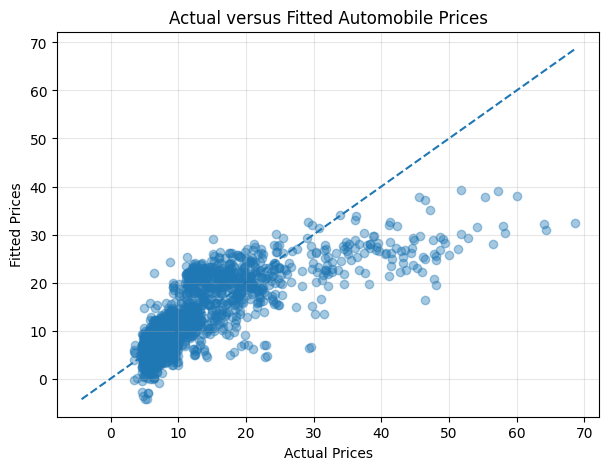

In [21]:
# Generate fitted prices from the first-stage regression.
df['fitted_prices'] = first_stage.fittedvalues

plt.figure(figsize=(7, 5))
plt.scatter(df['prices'], df['fitted_prices'], alpha=0.4)

# Add the 45-degree reference line.
limits = [
    min(df['prices'].min(), df['fitted_prices'].min()),
    max(df['prices'].max(), df['fitted_prices'].max())
]
plt.plot(limits, limits, linestyle='--')

plt.xlabel('Actual Prices')
plt.ylabel('Fitted Prices')
plt.title('Actual versus Fitted Automobile Prices')
plt.grid(alpha=0.3)
plt.show()

The scatter plot compares actual automobile prices against the fitted values predicted by the first-stage regression model. The data points track along the dashed 45-degree reference line in the lower-to-mid price range, confirming that the instruments $Z_{k,jt}$ and product characteristics $X_{jt}$ capture significant variation in actual prices. For highly-priced luxury vehicles (above 30), the fitted values flatten out below the line, indicating that the linear first-stage specification systematically underpredicts prices at extreme valuations.

### Model 2: IV/2SLS Demand Estimation

**First stage: Predict automobile prices.**
We regress actual automobile prices on the eight demand instruments and the five observed product characteristics:  
$$
p_{jt} = \pi_0+ \sum_{k=0}^{7}\pi_k Z_{k,jt} +X_{jt}'\gamma+v_{jt}
$$  
This produces a fitted price, $\widehat{p}_{jt}$, for every vehicle. The fitted price captures the variation in prices explained by the instruments and observed characteristics.

**Second stage: Estimate automobile demand using fitted prices.**  
We replace actual prices with their fitted values in the demand equation:  
$$
\log(s_{jt})-\log(s_{0t}) = \alpha\widehat{p}_{jt} +X_{jt}'\beta+\varepsilon_{jt}
$$  
The resulting coefficient, $\widehat{\alpha}_{2SLS}$, estimates the relationship between demand and the instrument-predicted component of prices, rather than relying on all observed price variation.



In [22]:
iv_model = IV2SLS.from_formula(
    'log_share_ratio ~ 1 + hpwt + air + mpd + mpg + space '
    '+ [prices ~ ' + ' + '.join(instruments) + ']',
    data=df
).fit(cov_type='robust')

print(iv_model.summary)

                          IV-2SLS Estimation Summary                          
Dep. Variable:        log_share_ratio   R-squared:                      0.3589
Estimator:                    IV-2SLS   Adj. R-squared:                 0.3572
No. Observations:                2217   F-statistic:                    874.84
Date:                Sat, Oct 31 2026   P-value (F-stat)                0.0000
Time:                        20:46:02   Distribution:                  chi2(6)
Cov. Estimator:                robust                                         
                                                                              
                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
Intercept     -11.173     0.3887    -28.742     0.0000     -11.935     -10.411
hpwt           1.6880     0.4284     3.9400     0.00

The IV/2SLS regression produces a negative and statistically significant price coefficient of -0.1338, indicating that a one-unit increase in automobile price is associated with an approximately 0.1338 decrease in the log market-share ratio, holding observed characteristics constant. The 95% confidence interval ranges from -0.1566 to -0.1111, excluding zero. Compared with the OLS estimate of -0.0884, the IV coefficient is larger in absolute magnitude, suggesting that accounting for potential price endogeneity results in a stronger estimated negative relationship between prices and demand. This difference between OLS and IV is consistent with the possibility that OLS understates consumers' price sensitivity, although the direction and source of the bias cannot be established from this comparison alone.

### Model Validation and Robustness

In [23]:
controls = ['hpwt', 'air', 'mpd', 'mpg', 'space']

same_firm_instruments = instruments[:4]
rival_instruments = instruments[4:]

def estimate_iv(instrument_list, estimator=IV2SLS):
    formula = (
        'log_share_ratio ~ 1 + ' + ' + '.join(controls)
        + ' + [prices ~ ' + ' + '.join(instrument_list) + ']'
    )
    return estimator.from_formula(formula, data=df).fit(cov_type='robust')

# Estimate alternative 2SLS specifications.
iv_same_firm = estimate_iv(same_firm_instruments)
iv_rival = estimate_iv(rival_instruments)

# Estimate LIML using all eight instruments.
liml_model = estimate_iv(instruments, estimator=IVLIML)

# Collect all specifications.
models = {
    'Full 2SLS': iv_model,
    'Same-firm 2SLS': iv_same_firm,
    'Rival-firm 2SLS': iv_rival,
    'Full LIML': liml_model
}

In [24]:
for name, model in models.items():
    print(f'\n{name}')
    print(model.first_stage.diagnostics)


Full 2SLS
        rsquared  partial.rsquared  shea.rsquared      f.stat        f.pval  \
prices   0.62787          0.148136       0.148136  291.888193  2.191039e-58   

         f.dist  
prices  chi2(8)  

Same-firm 2SLS
        rsquared  partial.rsquared  shea.rsquared      f.stat        f.pval  \
prices  0.611811          0.111375       0.111375  222.629751  5.093322e-47   

         f.dist  
prices  chi2(4)  

Rival-firm 2SLS
        rsquared  partial.rsquared  shea.rsquared      f.stat        f.pval  \
prices  0.602938          0.091063       0.091063  196.537089  2.086051e-41   

         f.dist  
prices  chi2(4)  

Full LIML
        rsquared  partial.rsquared  shea.rsquared      f.stat        f.pval  \
prices   0.62787          0.148136       0.148136  291.888193  2.191039e-58   

         f.dist  
prices  chi2(8)  


The first-stage diagnostics indicate that all three instrument sets are jointly relevant for explaining automobile prices after controlling for observed vehicle characteristics. The full set has the highest partial R-squared (0.1481), followed by the same-firm instruments (0.1114) and rival-firm instruments (0.0911). The reported test statistics are robust chi-squared statistics, rather than conventional F-statistics, and their very small p-values provide strong evidence against the null that the instruments are jointly irrelevant. The LIML model has identical first-stage diagnostics to full 2SLS because both use the same instruments and controls.

In [25]:
print('Full 2SLS:')
print(iv_model.wooldridge_overid)

print('\nSame-firm 2SLS:')
print(iv_same_firm.wooldridge_overid)

print('\nRival-firm 2SLS:')
print(iv_rival.wooldridge_overid)

Full 2SLS:
Wooldridge's score test of overidentification
H0: Model is not overidentified.
Statistic: 231.4950
P-value: 0.0000
Distributed: chi2(7)

Same-firm 2SLS:
Wooldridge's score test of overidentification
H0: Model is not overidentified.
Statistic: 188.4993
P-value: 0.0000
Distributed: chi2(3)

Rival-firm 2SLS:
Wooldridge's score test of overidentification
H0: Model is not overidentified.
Statistic: 75.8668
P-value: 0.0000
Distributed: chi2(3)


The overidentifying restrictions are rejected for all three instrument sets. The rival-firm set gives the smallest statistic, but none passes. Rejection means either some instruments are invalid or the logit specification is misspecified; the test cannot tell which.

In [26]:
comparison = []

# Include OLS.
ols_ci = ols_model.conf_int().loc['prices']

comparison.append({
    'Model': 'OLS',
    'Coefficient': ols_model.params['prices'],
    'Robust SE': ols_model.bse['prices'],
    'p-value': ols_model.pvalues['prices'],
    'CI Lower': ols_ci.iloc[0],
    'CI Upper': ols_ci.iloc[1]
})

# Include all IV specifications.
for name, model in models.items():
    ci = model.conf_int().loc['prices']

    comparison.append({
        'Model': name,
        'Coefficient': model.params['prices'],
        'Robust SE': model.std_errors['prices'],
        'p-value': model.pvalues['prices'],
        'CI Lower': ci.iloc[0],
        'CI Upper': ci.iloc[1]
    })
comparison_df = pd.DataFrame(comparison).set_index('Model')

comparison_display = comparison_df.copy()

comparison_display['p-value'] = comparison_display['p-value'].map(
    lambda p: f'{p:.2e}'
)

display(comparison_display.round(4))

,Coefficient,Robust SE,p-value,CI Lower,CI Upper
Model,,,,,
OLS,-0.0884,0.0044,8.06e-92,-0.0970,-0.0799
Full 2SLS,-0.1338,0.0116,8.94e-31,-0.1566,-0.1111
Same-firm 2SLS,-0.1661,0.0135,8.12e-35,-0.1925,-0.1396
Rival-firm 2SLS,-0.1930,0.0164,3.84e-32,-0.2250,-0.1609
Full LIML,-0.2189,0.0392,2.30e-08,-0.2957,-0.1421


Every IV estimate is more negative than OLS (−0.088), which is consistent with OLS being biased toward zero by unobserved product quality. But the IV estimates disagree with each other: −0.134 (full 2SLS), −0.166 (same-firm), −0.193 (rival-firm), and −0.219 (LIML). Valid instruments should give similar estimates, so this spread is another warning sign. The results are best read as a range of about −0.13 to −0.22, not as a single causal estimate.

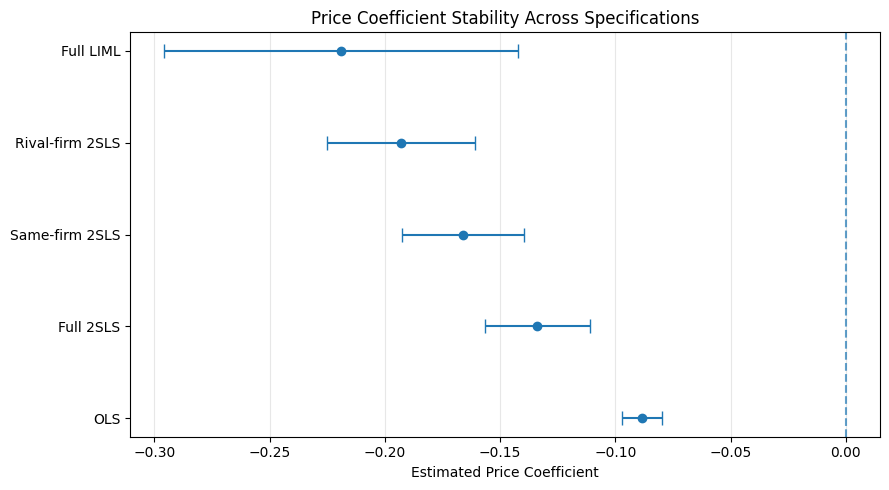

In [27]:
plot_data = comparison_df

plt.figure(figsize=(9, 5))

plt.errorbar(
    plot_data['Coefficient'],
    range(len(plot_data)),
    xerr=[
        plot_data['Coefficient'] - plot_data['CI Lower'],
        plot_data['CI Upper'] - plot_data['Coefficient']
    ],
    fmt='o',
    capsize=5
)

plt.axvline(0, linestyle='--', alpha=0.7)
plt.yticks(range(len(plot_data)), plot_data.index)
plt.xlabel('Estimated Price Coefficient')
plt.title('Price Coefficient Stability Across Specifications')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# OLS with firm FE, for an apples-to-apples comparison with IV + firm FE
ols_fe = smf.ols('log_share_ratio ~ prices + hpwt + air + mpd + mpg + space + C(firm_ids)',
                 data=df).fit(cov_type='HC1')
print('OLS, firm FE:', ols_fe.params['prices'])

# Store the IV + firm FE model so you can reuse it
f = ('log_share_ratio ~ 1 + ' + ' + '.join(controls + ['C(firm_ids)'])
     + ' + [prices ~ ' + ' + '.join(instruments) + ']')
iv_firm_fe = IV2SLS.from_formula(f, data=df).fit(cov_type='robust')

# Try firm + year FE with 4 instruments (all 8 are collinear)
for label, ilist in [('Same-firm 4', instruments[:4]), ('Rival 4', instruments[4:])]:
    try:
        f2 = ('log_share_ratio ~ 1 + ' + ' + '.join(controls + ['C(firm_ids)', 'C(market_ids)'])
              + ' + [prices ~ ' + ' + '.join(ilist) + ']')
        m = IV2SLS.from_formula(f2, data=df).fit(cov_type='robust')
        t = m.wooldridge_overid
        print(f"{label}: alpha={m.params['prices']:.4f}, stat={t.stat:.1f}, df={t.df}, p={t.pval:.4f}")
    except ValueError as e:
        print(label, 'failed:', e)

OLS, firm FE: -0.06775662011386817
Same-firm 4: alpha=-0.4218, stat=5.3, df=3, p=0.1521
Rival 4: alpha=-0.4218, stat=5.3, df=3, p=0.1521


Adding firm fixed effects alone lowers the OLS price coefficient to −0.068. With firm and year effects together (which requires four instruments, since all eight become collinear with the effects), the overidentification test no longer rejects (statistic 5.3, 3 df, p = 0.15) and the price coefficient is −0.42. This result should not be trusted: the first stage is very weak (partial R² of 0.004, joint test p = 0.052), so the test has almost no power and the estimate is likely imprecise and unreliable. Absorbing brand and year effects appears to remove the variation that makes the instruments valid, but also much of the variation that makes them informative.

### Firm and Year Fixed Effects (four instruments)

With both sets of fixed effects, all eight instruments become collinear with the dummies, so only the four same-firm instruments are used. The first-stage diagnostics below show whether they remain informative.

In [29]:
f = ('log_share_ratio ~ 1 + ' + ' + '.join(controls + ['C(firm_ids)', 'C(market_ids)'])
     + ' + [prices ~ ' + ' + '.join(instruments[:4]) + ']')
iv_fy = IV2SLS.from_formula(f, data=df).fit(cov_type='robust')

print(iv_fy.first_stage.diagnostics)
print(iv_fy.wooldridge_overid)
print(iv_fy.conf_int().loc['prices'])

a = iv_fy.params['prices']
e = a * df['prices'] * (1 - df['shares'])
S_f = df.groupby(['market_ids', 'firm_ids'])['shares'].transform('sum')
mc = df['prices'] + 1 / (a * (1 - S_f))
print(f"alpha={a:.4f}, mean |elast|={e.abs().mean():.2f}, "
      f"inelastic={(e.abs() < 1).mean():.0%}, negative MC={(mc < 0).mean():.0%}")

        rsquared  partial.rsquared  shea.rsquared    f.stat    f.pval   f.dist
prices  0.825793          0.004184       0.004184  9.369474  0.052499  chi2(4)
Wooldridge's score test of overidentification
H0: Model is not overidentified.
Statistic: 5.2848
P-value: 0.1521
Distributed: chi2(3)
lower   -0.702329
upper   -0.141254
Name: prices, dtype: float64
alpha=-0.4218, mean |elast|=4.96, inelastic=0%, negative MC=0%


The 95% confidence interval is [−0.70, −0.14]; conventional intervals can be unreliable with weak instruments

### Summary of Project

In [30]:
def summarize_spec(label, instr, fe_terms=()):
    rhs = ' + '.join(controls + list(fe_terms))
    f = f'log_share_ratio ~ 1 + {rhs} + [prices ~ {" + ".join(instr)}]'
    m = IV2SLS.from_formula(f, data=df).fit(cov_type='robust')
    a = m.params['prices']
    t = m.wooldridge_overid
    fs = m.first_stage.diagnostics.loc['prices']
    lo, hi = m.conf_int().loc['prices']
    elast = a * df['prices'] * (1 - df['shares'])
    mc = df['prices'] + 1 / (a * (1 - S_f))
    return {'Specification': label, 'alpha': a, 'CI low': lo, 'CI high': hi,
            'Overid stat': t.stat, 'df': t.df, 'Overid p': t.pval,
            'Partial R2': fs['partial.rsquared'], 'First-stage p': fs['f.pval'],
            'Inelastic (%)': 100 * (elast.abs() < 1).mean(),
            'Negative MC (%)': 100 * (mc < 0).mean()}

specs = [
    ('No FE, 8 instruments',          instruments,     ()),
    ('Year FE, 4 instruments',        instruments[:4], ('C(market_ids)',)),
    ('Firm FE, 8 instruments',        instruments,     ('C(firm_ids)',)),
    ('Firm + year FE, 4 instruments', instruments[:4], ('C(firm_ids)', 'C(market_ids)')),
]
spec_table = pd.DataFrame([summarize_spec(*s) for s in specs]).set_index('Specification')
display(spec_table.round(3))

,alpha,CI low,CI high,Overid stat,df,Overid p,Partial R2,First-stage p,Inelastic (%),Negative MC (%)
Specification,,,,,,,,,,
"No FE, 8 instruments",-0.134,-0.157,-0.111,231.495,7,0.000,0.148,0.000,35.138,36.671
"Year FE, 4 instruments",-0.155,-0.181,-0.129,211.328,3,0.000,0.118,0.000,20.839,22.959
"Firm FE, 8 instruments",-0.079,-0.109,-0.048,44.809,7,0.000,0.121,0.000,74.154,74.786
"Firm + year FE, 4 instruments",-0.422,-0.702,-0.141,5.285,3,0.152,0.004,0.052,0.000,0.000


### Marginal Cost Analysis

If firms set prices to maximize profit (Bertrand-Nash pricing), the logit demand model implies a markup for each vehicle. For a multi-product firm, the markup depends only on the price coefficient and on the firm's total share of the market:

$$
p_{jt} - mc_{jt} = -\frac{1}{\alpha\,(1 - S_{ft})}
$$

where $S_{ft}$ is the combined market share of all vehicles sold by firm $f$ in year $t$. Subtracting this markup from the observed price gives each vehicle's implied marginal cost. A negative value is economically impossible, so the share of vehicles with negative implied marginal cost serves as a check on whether a price coefficient is consistent with profit-maximizing behavior.

Under this assumption, the average implied markup is 11.5 price units for OLS, 7.6 for IV without fixed effects, and 13.0 for IV with firm fixed effects. These are roughly 65% to 110% of the mean vehicle price (11.76). The share of vehicles with negative implied marginal cost is 69% (OLS), 37% (IV, no fixed effects), 23% (IV, year effects), and 75% (IV, firm effects). These price coefficients (−0.08 to −0.16) are too small in magnitude to be consistent with profit-maximizing firms, because the logit requires a large markup to rationalize observed prices. Only the firm-and-year estimate (−0.42), which has no vehicles with negative implied marginal cost, avoids this problem, and that estimate rests on very weak instruments.

## Key Takeaways and Limitations

1. **Price endogeneity matters.** In like-for-like comparisons, IV estimates are more negative than OLS: −0.134 vs −0.088 without fixed effects, and −0.079 vs −0.068 with firm effects. This is consistent with unobserved quality raising both prices and demand, although the size of the gap depends heavily on the specification.

2. **The BLP instruments fail the overidentification test in every specification where they are strong.** The test rejects with all eight instruments, with the same-firm and rival-firm subsets, with year fixed effects, and with firm fixed effects (all p < 0.001). Rejection means either that some instruments are invalid or that the simple logit is misspecified; the test cannot tell which. Estimates range from −0.08 to −0.22 depending on the specification and instruments, which valid instruments would not produce.

3. **Fixing validity destroys strength.** Firm fixed effects reduce the overid statistic substantially, and firm and year effects together remove the rejection, but with firm and year effects the first stage collapses (partial R² = 0.004), so the test has little power and the estimate (−0.42, 95% CI −0.70 to −0.14) is unreliable. In the specifications tried, none delivers instruments that are both strong and plausibly exogenous.

4. **The simple logit gives economically implausible results.** For price coefficients between −0.08 and −0.16, between 21% and 74% of vehicles have inelastic demand and between 23% and 75% have negative implied marginal costs under Bertrand pricing. Only the weak-instrument estimate (−0.42) avoids this.

5. **The logit cannot show real substitution patterns.** Under independence of irrelevant alternatives, a price increase by one car raises demand for every other car by the same percentage regardless of similarity, and with market shares this small those effects are close to zero. No merger simulation is reported because its results would reflect this restriction.

**What this analysis can and cannot establish.** It shows that price endogeneity matters in this market and that the choice of instruments and fixed effects drives the results. It does not provide a reliable estimate of consumers' price sensitivity. The random-coefficients model of Berry, Levinsohn, and Pakes, designed for this setting, is the natural next step.

**Other limitations.** The data cover 1971 to 1990. The BLP instruments assume product characteristics are exogenous to demand shocks. Results come from one dataset and a limited set of specifications, and the overidentification test cannot separate invalid instruments from model misspecification.

In [34]:
!zip -qr figures.zip figures
from google.colab import files
files.download("figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>